<a href="https://colab.research.google.com/github/Vikuska31/Avito.Antibot/blob/main/LR4_2_Clustering_MNIST_FIXED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 4-2. Кластеризация MNIST

**Тема:** сравнительная оценка алгоритмов **KMeans**, **DBSCAN** и **AgglomerativeClustering** на наборе данных MNIST.

По заданию:
- используется **20 000** примеров обучающего множества MNIST;
- сравнение проводится **без снижения размерности**, после **PCA**, **t-SNE** и **UMAP**;
- для PCA обязательно применяется **StandardScaler**;
- качество оценивается по **ACC**, **NMI** и **Davies–Bouldin Score (DBS)**;
- время `t` считается как **время редуктора + время кластеризации**;
- выводятся гиперпараметры, визуализации найденных и истинных кластеров и итоговая таблица.

Во всех 12 экспериментах используется одна и та же выборка из 20 000 объектов.

## 1. Импорт библиотек

Подключаем библиотеки для работы с данными, кластеризации, снижения размерности, расчёта метрик и визуализации.

`umap-learn` нужен только для UMAP. Если пакет отсутствует, ноутбук попытается установить его автоматически.

In [1]:
import sys
import time
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.optimize import linear_sum_assignment

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    normalized_mutual_info_score,
    davies_bouldin_score,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

try:
    import umap
except ImportError:
    print("Пакет umap-learn не найден. Выполняется установка...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Библиотеки подключены.")

Python: 3.13.16
NumPy: 2.1.3
Библиотеки подключены.


## 2. Параметры эксперимента

Основные значения взяты из задания и примеров лекции.

Для `AgglomerativeClustering` используется **Ward linkage** без графа связности, как в лекции.

`eps` для DBSCAN не задаётся вручную: он подбирается автоматически в разделе 7 отдельно
для каждого представления, потому что масштаб расстояний в 784, 64 и 2 измерениях разный.

In [2]:
SEED = 42
N_SAMPLES = 20_000
N_CLASSES = 10

# Параметры редукторов
PCA_COMPONENTS = 64
TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 40
UMAP_COMPONENTS = 2
UMAP_N_NEIGHBORS = 30
UMAP_MIN_DIST = 0.0

# Параметры KMeans
KMEANS_N_INIT = 10
KMEANS_MAX_ITER = 300
KMEANS_TOL = 0.001

# Параметры DBSCAN: eps подбирается в разделе 7
DBSCAN_MIN_SAMPLES = 10
EPS_GRID_STEPS = 10
DBSCAN_EPS = {}

# AgglomerativeClustering
AGGLO_LINKAGE = "ward"

# Для читаемых рисунков можно показывать не все 20 000 точек.
PLOT_MAX_POINTS = 6_000

np.random.seed(SEED)

print("Объектов:", N_SAMPLES)
print("Классов:", N_CLASSES)
print("Linkage:", AGGLO_LINKAGE)

Объектов: 20000
Классов: 10
Linkage: ward


## 3. Загрузка обучающего множества MNIST

Сначала ищутся локальные файлы преподавателя:

- `images_trn.bin`
- `labels_trn.bin`

Если их нет, загружается стандартная **обучающая** часть MNIST (60 000 изображений). Из неё стратифицированно выбираются 20 000 объектов.

`X_raw` хранит исходные яркости `0...255`.  
`X_unit = X_raw / 255` — те же 784 признака, только в масштабе `[0, 1]`. Это **не снижение размерности**.

In [3]:
def load_mnist_train():
    # Возвращает обучающую часть MNIST: X формы (N, 784) и y формы (N,).

    # 1. Локальные bin-файлы из материалов преподавателя.
    search_dirs = [
        Path("."),
        Path("mnist"),
        Path("MNIST"),
        Path("data"),
        Path("data/mnist"),
    ]

    for folder in search_dirs:
        img_path = folder / "images_trn.bin"
        lbl_path = folder / "labels_trn.bin"

        if img_path.exists() and lbl_path.exists():
            X_local = np.fromfile(img_path, dtype=np.uint8).reshape(-1, 28 * 28)
            y_local = np.fromfile(lbl_path, dtype=np.uint8).astype(np.int64)

            if len(X_local) != len(y_local):
                raise ValueError("Число изображений и меток в bin-файлах не совпадает.")

            print("MNIST загружен из:", folder.resolve())
            return X_local.astype(np.float32), y_local

    # 2. Стандартный MNIST через torchvision.
    try:
        from torchvision.datasets import MNIST

        ds = MNIST(root="mnist_data", train=True, download=True)
        X_tv = ds.data.numpy().reshape(-1, 28 * 28).astype(np.float32)
        y_tv = ds.targets.numpy().astype(np.int64)

        print("MNIST загружен через torchvision (train=True).")
        return X_tv, y_tv

    except Exception as torchvision_error:
        print("torchvision не сработал:", type(torchvision_error).__name__)

    # 3. Резервный вариант через OpenML.
    try:
        from sklearn.datasets import fetch_openml

        X_oml, y_oml = fetch_openml(
            "mnist_784",
            version=1,
            return_X_y=True,
            as_frame=False,
        )

        # В стандартном MNIST первые 60 000 объектов — train-часть.
        X_oml = X_oml[:60_000].astype(np.float32)
        y_oml = y_oml[:60_000].astype(np.int64)

        print("MNIST загружен через OpenML; взяты первые 60 000 train-объектов.")
        return X_oml, y_oml

    except Exception as openml_error:
        raise RuntimeError(
            "Не удалось получить MNIST. Положите images_trn.bin и labels_trn.bin "
            "в папку mnist/ либо запустите ноутбук с доступом в интернет."
        ) from openml_error


X_train_all, y_train_all = load_mnist_train()

if len(X_train_all) < N_SAMPLES:
    raise ValueError(f"В обучающем наборе меньше {N_SAMPLES} объектов.")

# Стратифицированно выбираем именно 20 000 объектов.
X_raw, _, y, _ = train_test_split(
    X_train_all,
    y_train_all,
    train_size=N_SAMPLES,
    stratify=y_train_all,
    random_state=SEED,
)

X_raw = X_raw.astype(np.float32)
y = y.astype(np.int64)
X_unit = X_raw / 255.0

assert X_raw.shape == (N_SAMPLES, 784)
assert y.shape == (N_SAMPLES,)

print("X_raw:", X_raw.shape)
print("y:", y.shape)
print("Яркость:", float(X_raw.min()), "...", float(X_raw.max()))

print("\nКоличество объектов каждого класса:")
display(pd.Series(y).value_counts().sort_index().rename("Количество").to_frame())

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 487kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.50MB/s]


MNIST загружен через torchvision (train=True).
X_raw: (20000, 784)
y: (20000,)
Яркость: 0.0 ... 255.0

Количество объектов каждого класса:


,Количество
0,1974
1,2247
2,1986
3,2044
4,1948
5,1807
6,1973
7,2088
8,1950
9,1983


## 4. Визуальная проверка исходных данных

Каждый объект MNIST — вектор из `784 = 28 × 28` значений яркости. Покажем по одному примеру каждой цифры.

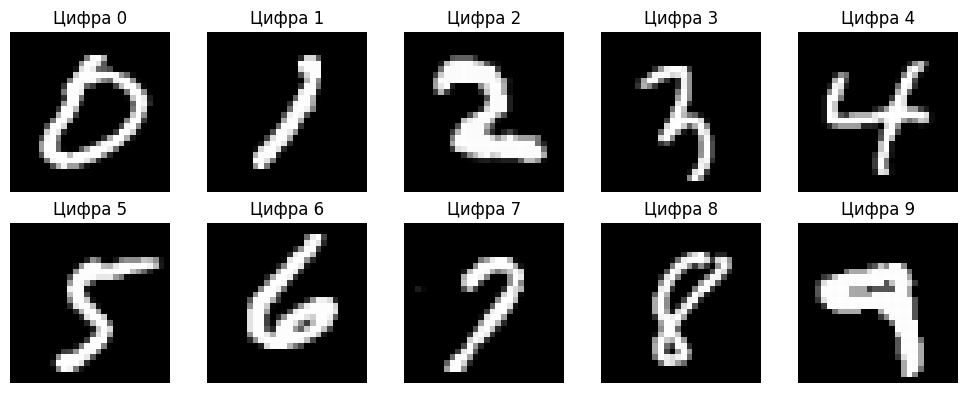

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.ravel()):
    idx = np.where(y == digit)[0][0]
    ax.imshow(X_raw[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Цифра {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Метрики качества

### ACC
ID найденного кластера не обязан совпадать с цифрой. Поэтому перед ACC номера кластеров
сопоставляются истинным меткам через `linear_sum_assignment`, как в лекции.

Для DBSCAN метка `-1` означает шум и не сопоставляется цифре, то есть все точки шума
попадают в ACC как ошибки.

### NMI
`Normalized Mutual Information` лежит в диапазоне `0...1`; больше — лучше.
Для DBSCAN шум считается отдельным кластером: NMI вычисляется по исходным меткам,
включая `-1`.

### DBS
`Davies–Bouldin Score` — внутренняя метрика; реальные метки не нужны. Меньше — лучше.
Для DBSCAN шум исключается из DBS.

DBS вычисляется по геометрии того пространства, в котором работал алгоритм,
поэтому значения для 784, 64 и 2 признаков между собой несопоставимы и сравниваются
только внутри одного представления.

In [5]:
def align_cluster_labels(y_true, y_pred):
    # Сопоставляет номера найденных кластеров истинным цифрам.
    # DBSCAN-шум (-1) остаётся -1.
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)

    pred_labels = [label for label in np.unique(y_pred) if label != -1]
    true_labels = list(np.unique(y_true))

    aligned = np.full_like(y_pred, -1)

    if len(pred_labels) == 0:
        return aligned, {}

    # W[i, j] = число объектов найденного кластера i,
    # которые реально принадлежат классу j.
    W = np.zeros((len(pred_labels), len(true_labels)), dtype=np.int64)

    pred_to_row = {label: i for i, label in enumerate(pred_labels)}
    true_to_col = {label: j for j, label in enumerate(true_labels)}

    for pred_label, true_label in zip(y_pred, y_true):
        if pred_label != -1:
            W[pred_to_row[pred_label], true_to_col[true_label]] += 1

    row_ind, col_ind = linear_sum_assignment(W, maximize=True)

    mapping = {
        pred_labels[row]: true_labels[col]
        for row, col in zip(row_ind, col_ind)
    }

    for cluster_label, digit_label in mapping.items():
        aligned[y_pred == cluster_label] = digit_label

    return aligned, mapping


def clustering_acc(y_true, y_pred):
    aligned, mapping = align_cluster_labels(y_true, y_pred)
    acc_value = np.mean(aligned == np.asarray(y_true))
    return float(acc_value), aligned, mapping


def safe_davies_bouldin(X_used, y_pred):
    # Шум DBSCAN (-1) не считаем отдельным кластером.
    y_pred = np.asarray(y_pred)
    mask = y_pred != -1

    labels = np.unique(y_pred[mask])
    n_objects = int(mask.sum())

    if n_objects < 2 or len(labels) < 2 or len(labels) >= n_objects:
        return np.nan

    return float(davies_bouldin_score(X_used[mask], y_pred[mask]))


def evaluate_clustering(X_used, y_true, y_pred):
    acc_value, aligned, mapping = clustering_acc(y_true, y_pred)

    nmi_value = float(
        normalized_mutual_info_score(y_true, y_pred)
    )

    dbs_value = safe_davies_bouldin(X_used, y_pred)

    unique_pred = np.unique(y_pred)
    n_clusters = len(unique_pred) - int(-1 in unique_pred)
    noise_percent = float(np.mean(np.asarray(y_pred) == -1) * 100.0)

    return {
        "ACC": acc_value,
        "NMI": nmi_value,
        "DBS": dbs_value,
        "Найдено кластеров": n_clusters,
        "Шум, %": noise_percent,
        "aligned": aligned,
        "mapping": mapping,
    }


# Мини-тест ACC: разбиение одинаковое, но номера кластеров переставлены.
_test_true = np.array([0, 0, 1, 1, 2, 2])
_test_pred = np.array([2, 2, 0, 0, 1, 1])

_test_acc, _test_aligned, _test_map = clustering_acc(_test_true, _test_pred)

assert np.isclose(_test_acc, 1.0)
assert np.array_equal(_test_aligned, _test_true)

print("Проверка ACC пройдена.")
print("Найденное соответствие:", _test_map)

Проверка ACC пройдена.
Найденное соответствие: {np.int64(0): np.int64(1), np.int64(1): np.int64(2), np.int64(2): np.int64(0)}


## 6. Подготовка четырёх представлений данных

Создаём:

1. 784 признака — без снижения размерности;
2. PCA — 64 компоненты;
3. t-SNE — 2 компоненты;
4. UMAP — 2 компоненты.

Время каждого редуктора измеряется отдельно.

In [6]:
representation_order_names = [
    "Без снижения размерности",
    "PCA",
    "t-SNE",
    "UMAP",
]

representations = {}
reducer_times = {}
visual_2d = {}
reducers = {}

# ------------------------------------------------------------
# 1. БЕЗ СНИЖЕНИЯ РАЗМЕРНОСТИ
# ------------------------------------------------------------
# Размерность остаётся 784. Деление на 255 только меняет масштаб яркости.
representations["Без снижения размерности"] = X_unit
reducer_times["Без снижения размерности"] = 0.0

# Только для рисунка нужна 2D-проекция.
# Она не участвует в кластеризации и не входит в время t.
visual_2d["Без снижения размерности"] = PCA(
    n_components=2,
    random_state=SEED,
).fit_transform(X_unit)

print("Без снижения:", representations["Без снижения размерности"].shape)

Без снижения: (20000, 784)


### 6.1. PCA

Перед PCA обязательно выполняется `StandardScaler`. В замер редуктора входит и стандартизация, и PCA.

In [7]:
t0 = time.perf_counter()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

pca_reducer = PCA(
    n_components=PCA_COMPONENTS,
    random_state=SEED,
)
X_pca = pca_reducer.fit_transform(X_scaled)

pca_time = time.perf_counter() - t0

X_pca = X_pca.astype(np.float32)

representations["PCA"] = X_pca
reducer_times["PCA"] = pca_time
visual_2d["PCA"] = X_pca[:, :2]
reducers["PCA"] = pca_reducer

print("PCA:", X_pca.shape)
print(f"StandardScaler + PCA: {pca_time:.3f} сек.")
print(
    f"Объяснённая дисперсия {PCA_COMPONENTS} компонент: "
    f"{pca_reducer.explained_variance_ratio_.sum():.4f}"
)

PCA: (20000, 64)
StandardScaler + PCA: 0.670 сек.
Объяснённая дисперсия 64 компонент: 0.6288


### 6.2. t-SNE

Параметры по лекции: `n_components=2`, `perplexity=40`, `random_state=42`.

In [8]:
t0 = time.perf_counter()

tsne_reducer = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    random_state=SEED,
    init="pca",
    learning_rate="auto",
    n_jobs=-1,
)

X_tsne = tsne_reducer.fit_transform(X_unit)
tsne_time = time.perf_counter() - t0

X_tsne = X_tsne.astype(np.float32)

representations["t-SNE"] = X_tsne
reducer_times["t-SNE"] = tsne_time
visual_2d["t-SNE"] = X_tsne
reducers["t-SNE"] = tsne_reducer

print("t-SNE:", X_tsne.shape)
print(f"Время t-SNE: {tsne_time:.3f} сек.")

t-SNE: (20000, 2)
Время t-SNE: 324.290 сек.


### 6.3. UMAP

Параметры по лекции: `n_neighbors=30`, `min_dist=0.0`, двумерное представление.

In [9]:
t0 = time.perf_counter()

umap_reducer = umap.UMAP(
    n_components=UMAP_COMPONENTS,
    n_neighbors=UMAP_N_NEIGHBORS,
    min_dist=UMAP_MIN_DIST,
    random_state=SEED,
)

X_umap = umap_reducer.fit_transform(X_unit)
umap_time = time.perf_counter() - t0

X_umap = X_umap.astype(np.float32)

representations["UMAP"] = X_umap
reducer_times["UMAP"] = umap_time
visual_2d["UMAP"] = X_umap
reducers["UMAP"] = umap_reducer

print("UMAP:", X_umap.shape)
print(f"Время UMAP: {umap_time:.3f} сек.")

UMAP: (20000, 2)
Время UMAP: 53.312 сек.


## 7. Подбор eps для DBSCAN

`min_samples = 10` одинаков для всех представлений, а `eps` подбирается автоматически:
ищется значение, при котором DBSCAN находит ровно 10 кластеров.

Диапазон поиска берётся из лекции — по расстояниям до 10-го ближайшего соседа,
от 1-го до 90-го процентиля. Внутри диапазона перебирается сетка значений, и выбирается
то, при котором число кластеров равно 10; если точного совпадения нет — ближайшее к 10.

Бинарный поиск здесь не используется: число найденных кластеров не убывает монотонно
с ростом `eps` (при очень маленьком `eps` почти все точки становятся шумом), поэтому
деление отрезка пополам может увести в сторону.

Подбор `eps` — это настройка гиперпараметра, в замер времени `t` он не входит.

Для 784 и 64 признаков подбор занимает заметное время: на каждое значение сетки
выполняется полный прогон DBSCAN.

In [ ]:
from sklearn.neighbors import NearestNeighbors


def dbscan_eps(X, n_classes, min_samples=DBSCAN_MIN_SAMPLES, steps=EPS_GRID_STEPS):
    # Подбирает eps, при котором DBSCAN находит n_classes кластеров.
    neighbors = NearestNeighbors(n_neighbors=min_samples, n_jobs=-1)
    distances, _ = neighbors.fit(X).kneighbors(X)
    distances = np.sort(distances[:, min_samples - 1])

    eps_min = distances[int(0.01 * len(distances))]
    eps_max = distances[int(0.90 * len(distances))]

    best_eps = eps_min
    best_diff = None

    for eps in np.linspace(eps_min, eps_max, steps):
        labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(X)
        n_clusters = len(np.unique(labels)) - int(-1 in labels)
        noise = np.mean(labels == -1) * 100.0

        print(f"    eps={eps:.4f}: кластеров {n_clusters}, шум {noise:.1f}%")

        diff = abs(n_clusters - n_classes)

        if best_diff is None or diff < best_diff:
            best_eps = eps
            best_diff = diff

        if n_clusters == n_classes:
            break

    return float(best_eps)


for representation_name in representation_order_names:
    print(representation_name)
    DBSCAN_EPS[representation_name] = dbscan_eps(
        representations[representation_name],
        N_CLASSES,
    )
    print("  Выбрано eps =", round(DBSCAN_EPS[representation_name], 4))

## 8. Гиперпараметры алгоритмов

KMeans и AgglomerativeClustering получают `n_clusters = 10`.
DBSCAN число кластеров не задаётся: он определяет его сам по `eps` и `min_samples`.

In [ ]:
hyperparameters = pd.DataFrame(
    [
        {
            "Алгоритм": "KMeans",
            "Параметры": (
                f"n_clusters={N_CLASSES}, n_init={KMEANS_N_INIT}, "
                f"max_iter={KMEANS_MAX_ITER}, tol={KMEANS_TOL}, "
                f"random_state={SEED}"
            ),
        },
        {
            "Алгоритм": "AgglomerativeClustering",
            "Параметры": f"n_clusters={N_CLASSES}, linkage='{AGGLO_LINKAGE}'",
        },
    ]
    + [
        {
            "Алгоритм": f"DBSCAN / {representation_name}",
            "Параметры": (
                f"eps={DBSCAN_EPS[representation_name]:.4f}, "
                f"min_samples={DBSCAN_MIN_SAMPLES}"
            ),
        }
        for representation_name in representation_order_names
    ]
)

display(hyperparameters)

## 9. Функции запуска алгоритмов

AgglomerativeClustering использует `ward` без графа связности.

In [ ]:
def fit_kmeans(X_used):
    model = KMeans(
        n_clusters=N_CLASSES,
        n_init=KMEANS_N_INIT,
        max_iter=KMEANS_MAX_ITER,
        tol=KMEANS_TOL,
        random_state=SEED,
    )
    labels = model.fit_predict(X_used)
    return labels, model


def fit_dbscan(X_used, representation_name):
    model = DBSCAN(
        eps=DBSCAN_EPS[representation_name],
        min_samples=DBSCAN_MIN_SAMPLES,
        n_jobs=-1,
    )
    labels = model.fit_predict(X_used)
    return labels, model


def fit_agglomerative(X_used):
    model = AgglomerativeClustering(
        n_clusters=N_CLASSES,
        linkage=AGGLO_LINKAGE,
    )
    labels = model.fit_predict(X_used)
    return labels, model


print("Функции кластеризации определены.")

## 10. Запуск всех 12 экспериментов

Для каждого представления запускаются:

1. AgglomerativeClustering;
2. DBSCAN;
3. KMeans.

`t, сек.` = время редуктора + время конкретной кластеризации.
Подбор `eps` и построение проекций для рисунков в это время не входят.

In [ ]:
results = []
predictions = {}
models = {}

algorithm_order = [
    "Agglomerative Clustering",
    "DBSCAN",
    "KMeans",
]

representation_order = representation_order_names

for representation_name in representation_order:
    X_used = representations[representation_name]

    print("\n" + "=" * 95)
    print(
        f"{representation_name}: "
        f"{X_used.shape[0]} объектов × {X_used.shape[1]} признаков"
    )
    print(f"Время редуктора: {reducer_times[representation_name]:.3f} сек.")

    for algorithm_name in algorithm_order:
        print(f"  {algorithm_name:<28}", end="")

        t0 = time.perf_counter()

        if algorithm_name == "KMeans":
            y_pred, model = fit_kmeans(X_used)
        elif algorithm_name == "DBSCAN":
            y_pred, model = fit_dbscan(X_used, representation_name)
        else:
            y_pred, model = fit_agglomerative(X_used)

        clustering_time = time.perf_counter() - t0
        total_time = reducer_times[representation_name] + clustering_time

        metrics = evaluate_clustering(
            X_used=X_used,
            y_true=y,
            y_pred=y_pred,
        )

        key = (representation_name, algorithm_name)

        predictions[key] = {
            "raw": np.asarray(y_pred),
            "aligned": metrics["aligned"],
            "mapping": metrics["mapping"],
        }
        models[key] = model

        results.append(
            {
                "Редуктор": representation_name,
                "Алгоритм": algorithm_name,
                "ACC": metrics["ACC"],
                "NMI": metrics["NMI"],
                "DBS": metrics["DBS"],
                "t, сек.": total_time,
                "Время редуктора, сек.": reducer_times[representation_name],
                "Время кластеризации, сек.": clustering_time,
                "Найдено кластеров": metrics["Найдено кластеров"],
                "Шум, %": metrics["Шум, %"],
            }
        )

        dbs_text = (
            f"{metrics['DBS']:.4f}"
            if np.isfinite(metrics["DBS"])
            else "NaN"
        )

        print(
            f" ACC={metrics['ACC']:.4f}"
            f" | NMI={metrics['NMI']:.4f}"
            f" | DBS={dbs_text}"
            f" | clusters={metrics['Найдено кластеров']}"
            f" | noise={metrics['Шум, %']:.2f}%"
            f" | t={total_time:.2f} сек."
        )

results_df = pd.DataFrame(results)

assert len(results_df) == 12
print("\nГотово: выполнено 12 экспериментов.")

## 11. Итоговая таблица по форме задания

Основная таблица содержит требуемые **ACC, NMI, DBS, t** для всех 12 комбинаций.

In [ ]:
results_df["Редуктор"] = pd.Categorical(
    results_df["Редуктор"],
    categories=representation_order,
    ordered=True,
)
results_df["Алгоритм"] = pd.Categorical(
    results_df["Алгоритм"],
    categories=algorithm_order,
    ordered=True,
)

results_df = (
    results_df
    .sort_values(["Редуктор", "Алгоритм"])
    .reset_index(drop=True)
)

main_table = results_df[
    ["Редуктор", "Алгоритм", "ACC", "NMI", "DBS", "t, сек."]
].copy()

main_table["ACC"] = main_table["ACC"].round(4)
main_table["NMI"] = main_table["NMI"].round(4)
main_table["DBS"] = main_table["DBS"].round(4)
main_table["t, сек."] = main_table["t, сек."].round(3)

display(main_table)

print("\nДополнительная диагностическая таблица:")
diagnostic_table = results_df[
    [
        "Редуктор",
        "Алгоритм",
        "Найдено кластеров",
        "Шум, %",
        "Время редуктора, сек.",
        "Время кластеризации, сек.",
    ]
].copy()

for column in ["Шум, %", "Время редуктора, сек.", "Время кластеризации, сек."]:
    diagnostic_table[column] = diagnostic_table[column].round(3)

display(diagnostic_table)

## 12. Визуализация найденных и истинных кластеров

Для каждого пространства показываются:

- Ground Truth;
- AgglomerativeClustering;
- DBSCAN;
- KMeans.

Для DBSCAN выводятся его собственные метки кластеров, а не сопоставленные цифрам:
шум (`-1`) рисуется крестиками.

Для исходных 784 признаков используется отдельная PCA-проекция только для рисунка;
в эксперимент и время она не входит.

In [ ]:
def choose_plot_indices(n_objects, max_points=PLOT_MAX_POINTS):
    if n_objects <= max_points:
        return np.arange(n_objects)

    rng = np.random.default_rng(SEED)
    return np.sort(
        rng.choice(n_objects, size=max_points, replace=False)
    )


def scatter_labels(ax, coords, labels, title, idx):
    labels = np.asarray(labels)
    coords = np.asarray(coords)

    normal = labels[idx] >= 0
    noise = labels[idx] == -1

    if np.any(normal):
        ax.scatter(
            coords[idx[normal], 0],
            coords[idx[normal], 1],
            c=labels[idx[normal]],
            s=6,
            alpha=0.65,
            vmin=0,
            vmax=max(9, int(labels.max())),
        )

    if np.any(noise):
        ax.scatter(
            coords[idx[noise], 0],
            coords[idx[noise], 1],
            s=8,
            marker="x",
            alpha=0.6,
        )

    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")


plot_idx = choose_plot_indices(len(y))

for representation_name in representation_order:
    coords = visual_2d[representation_name]

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))

    scatter_labels(
        axes[0],
        coords,
        y,
        "Ground Truth",
        plot_idx,
    )

    for ax, algorithm_name in zip(axes[1:], algorithm_order):
        prediction = predictions[(representation_name, algorithm_name)]

        # У DBSCAN показываем его собственные метки вместе с шумом.
        if algorithm_name == "DBSCAN":
            labels_to_plot = prediction["raw"]
        else:
            labels_to_plot = prediction["aligned"]

        scatter_labels(
            ax,
            coords,
            labels_to_plot,
            algorithm_name,
            plot_idx,
        )

    fig.suptitle(representation_name)
    plt.tight_layout()
    plt.show()

## 13. Автоматический анализ результатов

Определяем:
- максимальный ACC;
- максимальный NMI;
- минимальное полное время;
- минимальный DBS отдельно внутри каждого представления.

Таблица времени нужна для анализа влияния снижения размерности.

In [ ]:
best_acc_row = results_df.loc[results_df["ACC"].idxmax()]
best_nmi_row = results_df.loc[results_df["NMI"].idxmax()]
fastest_row = results_df.loc[results_df["t, сек."].idxmin()]

print(
    "Максимальный ACC:",
    f"{best_acc_row['Редуктор']} + {best_acc_row['Алгоритм']}",
    f"= {best_acc_row['ACC']:.4f}",
)
print(
    "Максимальный NMI:",
    f"{best_nmi_row['Редуктор']} + {best_nmi_row['Алгоритм']}",
    f"= {best_nmi_row['NMI']:.4f}",
)
print(
    "Минимальное полное время:",
    f"{fastest_row['Редуктор']} + {fastest_row['Алгоритм']}",
    f"= {fastest_row['t, сек.']:.3f} сек.",
)

# DBS зависит от размерности пространства, поэтому сравнивается
# только внутри одного представления.
print("\nМинимальный DBS внутри представления:")

valid_dbs = results_df.dropna(subset=["DBS"])

for representation_name in representation_order:
    part = valid_dbs[valid_dbs["Редуктор"] == representation_name]

    if len(part) == 0:
        print(f"  {representation_name}: DBS не определён")
        continue

    row = part.loc[part["DBS"].idxmin()]
    print(f"  {representation_name}: {row['Алгоритм']} = {row['DBS']:.4f}")

print("\nПолное время t = reducer + clustering:")
time_table = results_df.pivot(
    index="Алгоритм",
    columns="Редуктор",
    values="t, сек.",
).round(3)

display(time_table)

## 14. Какие цифры путаются чаще всего

Для каждой комбинации выводится самая частая ошибка `истинная цифра → найденная цифра`.

Дополнительно строится матрица ошибок для комбинации с максимальным ACC.

In [ ]:
confusion_rows = []

for representation_name in representation_order:
    for algorithm_name in algorithm_order:
        aligned = predictions[
            (representation_name, algorithm_name)
        ]["aligned"]

        error_mask = aligned != y

        if np.any(error_mask):
            error_pairs = (
                pd.DataFrame(
                    {
                        "Истинная": y[error_mask],
                        "Найденная": aligned[error_mask],
                    }
                )
                .value_counts()
                .reset_index(name="Количество")
            )

            top_error = error_pairs.iloc[0]

            confusion_rows.append(
                {
                    "Редуктор": representation_name,
                    "Алгоритм": algorithm_name,
                    "Чаще всего": (
                        f"{int(top_error['Истинная'])} → "
                        f"{int(top_error['Найденная'])}"
                    ),
                    "Количество": int(top_error["Количество"]),
                }
            )
        else:
            confusion_rows.append(
                {
                    "Редуктор": representation_name,
                    "Алгоритм": algorithm_name,
                    "Чаще всего": "ошибок нет",
                    "Количество": 0,
                }
            )

confusion_summary = pd.DataFrame(confusion_rows)
display(confusion_summary)

# Матрица ошибок для лучшей комбинации по ACC.
best_key = (
    str(best_acc_row["Редуктор"]),
    str(best_acc_row["Алгоритм"]),
)
best_aligned = predictions[best_key]["aligned"]

cm = confusion_matrix(
    y,
    best_aligned,
    labels=np.arange(10),
)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm)

ax.set_title(
    "Матрица ошибок для максимального ACC\n"
    f"{best_key[0]} + {best_key[1]}"
)
ax.set_xlabel("Найденная цифра")
ax.set_ylabel("Истинная цифра")
ax.set_xticks(np.arange(10))
ax.set_yticks(np.arange(10))

for i in range(10):
    for j in range(10):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7)

plt.tight_layout()
plt.show()

## 15. Сохранение результатов

Таблицы сохраняются в папку `lab4_2_results`, чтобы их можно было использовать в отчёте
без повторного долгого запуска.

In [ ]:
OUT_DIR = Path("lab4_2_results")
OUT_DIR.mkdir(exist_ok=True)

main_table.to_csv(
    OUT_DIR / "clustering_results.csv",
    index=False,
    encoding="utf-8-sig",
)
diagnostic_table.to_csv(
    OUT_DIR / "clustering_diagnostics.csv",
    index=False,
    encoding="utf-8-sig",
)
hyperparameters.to_csv(
    OUT_DIR / "hyperparameters.csv",
    index=False,
    encoding="utf-8-sig",
)
confusion_summary.to_csv(
    OUT_DIR / "top_confusions.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Результаты сохранены в:", OUT_DIR.resolve())

## 16. Что писать в выводе после запуска

Вывод делается **по реально полученной таблице**, без заранее заданного «победителя»:

1. назвать комбинацию с максимальным ACC;
2. назвать комбинацию с максимальным NMI;
3. указать минимальный DBS внутри каждого представления;
4. сравнить полное время `t`;
5. для DBSCAN отметить подобранное `eps`, число найденных кластеров и процент шума;
6. назвать цифры, которые смешиваются чаще всего.

### Что важно помнить для защиты

- **KMeans** — центроидный метод; лучше подходит для компактных, близких к сферическим кластеров.
- **DBSCAN** — плотностный метод; число кластеров заранее не задаётся, шум имеет метку `-1`; ключевые параметры — `eps` и `min_samples`.
- **AgglomerativeClustering** — иерархический агломеративный метод; здесь используется `ward`.
- **PCA** — линейный метод; перед ним применяется `StandardScaler`.
- **t-SNE** и **UMAP** — нелинейные методы; t-SNE сильнее сохраняет локальную структуру, UMAP лучше сохраняет и взаимное расположение крупных групп.
- **ACC и NMI** — внешние метрики, им нужен Ground Truth.
- **DBS** — внутренняя метрика, Ground Truth ей не нужен; её значения сопоставимы только внутри одного пространства признаков.
- Для **ACC** ID кластеров сначала сопоставляются истинным цифрам.
- Хорошие **ACC/NMI** стремятся к `1`, хороший **DBS** — к меньшему значению.